# Candidate Generation - Niche Two-Tower MLP

This notebook trains a content-based niche candidate-generation model and uses the rolling popularity baseline's Top-200 list as the popular reference for exclusion and niche-click evaluation. The combined candidate list is produced by the combined notebook.

- **Popular reference:** Uses the rolling popularity baseline's previous-hour Top-200 list to exclude popular articles and define niche clicks; the popular list is not emitted here.
- **Niche channel:** Uses a two-tower neural network to retrieve relevant articles outside the popular list, based on reading history, article content, and freshness.

The article tower encodes text, entities, categories, and subcategories. The user tower applies attention pooling to previously read articles. Their embeddings are compared, with a learned freshness adjustment, to rank niche candidates without using click or display counts as neural inputs.

**Objective:** Retrieve relevant articles overlooked by the popularity baseline and produce complementary candidates for downstream reranking. Article availability and past interactions are respected to prevent future-information leakage.

Run `CG_rolling_popularity_baseline.ipynb` for validation before this notebook so its saved popularity recommendations are available.


## Step 1: Setup and Reproducibility

Import the required libraries, define project and output directories, and set random seeds for reproducibility. Configure model hyperparameters, evaluation settings, and experiment switches. Load the group's shared negative-sampling, evaluation, and result-writing utilities.


In [23]:
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')   # Let numpy and torch share one maths library on Windows

import copy
import random
import sys
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torch.nn as nn
import torch.nn.functional as F

# Set random seeds to ensure reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)

# Run on the GPU when one is available
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)

# Locate the project folder and load the shared evaluator and writer
ENVIRONMENT = 'local'  # 'local' or 'colab'

if ENVIRONMENT == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')
    CODE_ROOT = Path('/content/drive/MyDrive/BT4222-Group-6-')
    ROOT = Path('/content/drive/MyDrive/v3-mindsmall')
else:
    CODE_ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'run_all.py').is_file()
    )
    ROOT = Path(os.environ.get('NEWSREC_ROOT', CODE_ROOT)).expanduser().resolve()

CG_DIR = ROOT / '5_Models' / '5_01_Candidate_Generation'
CG_CODE_DIR = CODE_ROOT / '5_Models' / '5_01_Candidate_Generation'
sys.path.insert(0, str(CG_CODE_DIR))
sys.path.insert(0, str(CG_CODE_DIR / 'baseline_models'))
from cg_evaluation import CandidateEvaluator, wide_table
from cg_result_writer import CandidateWriter

# Project package: fresh shown-but-not-clicked negatives for every epoch
sys.path.insert(0, str(CODE_ROOT / 'src'))
from newsrec.training import iter_training_epoch

# Input and output folders
PROCESSED = ROOT / '1_Data_Preparation' / 'processed'
REPRESENTATIONS = ROOT / '3_Representations' / 'artifacts'
FEATURES = ROOT / '4_Feature_Engineering' / 'artifacts' / 'prequential-all'
POPULAR_DIR = CG_DIR / 'artifacts' / 'popularity_freshness_prior_hour_clicks'
OUTPUT_DIR = CG_DIR / 'artifacts' / 'niche_two_tower'
RESULTS = ROOT / 'results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
MODEL_NAME = 'niche_two_tower'

# Training and selection switches
NEGATIVE_SOURCE = 'shown'   # 'random', 'shown' (redrawn each epoch by iter_training_epoch) or 'both'
NEGATIVES = 'all_articles'     # 'niche_pool' or 'all_articles'
TRAIN_ON = 'all'             # 'all' or 'niche_only'
LOSS = 'bpr'             # 'softmax' or 'bpr'
SELECT_BY = 'ndcg'           # 'ndcg' or 'recall'

# Channel sizes and evaluation cutoffs
POPULAR_TOP_N = 200                                # size of the popular shelf
NICHE_DEPTH = 750                                  # niche articles saved per request
EVAL_M = tuple(range(50, NICHE_DEPTH + 1, 50))     # cutoffs in the results CSV
NDCG_K = 300                                       # cutoff for long-tail NDCG
RECALL_K = 300                                     # cutoff for long-tail recall
SWEEP_K = (50, 100, 200, 300)                      # recall cutoffs reported in the niche metrics

# Model and training settings
DIM = 64                   # size of user and article vectors
MAX_HISTORY = 50           # most recent history articles read by the user tower
N_NEG = 4                  # random negatives per click (1:4)
N_SHOWN = 4                # shown-but-not-clicked negatives per click, redrawn each epoch (1:4)
BATCH = 512                # clicks per training batch
LEARNING_RATE = 1e-3
EPOCHS = 20
PATIENCE = 3               # stop after this many epochs without improvement
TEMPERATURE = 0.05         # sharpness of the similarity score
FRESH_BUCKETS = 12         # article-age groups for the freshness bonus
EARLY_STOP_SAMPLE = 8_000  # validation requests checked after each epoch
SCORE_BATCH = 256          # requests scored at once
HOUR_NS = 3_600 * 10**9

for name, value, options in (('NEGATIVE_SOURCE', NEGATIVE_SOURCE, ('random', 'shown', 'both')),
                             ('NEGATIVES', NEGATIVES, ('niche_pool', 'all_articles')),
                             ('TRAIN_ON', TRAIN_ON, ('all', 'niche_only')),
                             ('LOSS', LOSS, ('softmax', 'bpr')),
                             ('SELECT_BY', SELECT_BY, ('ndcg', 'recall'))):
    if value not in options:
        raise ValueError(f'{name} must be one of {options}')

NDCG_NAME = f'long_tail_ndcg@{NDCG_K}'
RECALL_NAME = f'long_tail_recall@{RECALL_K}'
SELECT_METRIC = NDCG_NAME if SELECT_BY == 'ndcg' else RECALL_NAME
RECALL_KS = tuple(sorted(set(SWEEP_K) | {RECALL_K}))

print('Project:', ROOT)
print('Evaluator:', sys.modules['cg_evaluation'].__file__)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '(CPU only)')
print(f'Settings: negative_source={NEGATIVE_SOURCE} | negatives={NEGATIVES} | train_on={TRAIN_ON} | loss={LOSS} | select_by={SELECT_METRIC}')

Project: c:\Users\Yong Rui\BT4222-Group-6-
Evaluator: c:\Users\Yong Rui\BT4222-Group-6-\5_Models\5_01_Candidate_Generation\cg_evaluation.py
Device: cuda AMD Radeon RX 9070 XT
Settings: negative_source=shown | negatives=all_articles | train_on=all | loss=bpr | select_by=long_tail_ndcg@300


## Step 2: Load and Prepare Article Features

Load article text and entity embeddings, categories, subcategories, and availability timestamps from the earlier data-processing stages. Validate row alignment, encode categorical values, and create mappings between article identifiers and model row indices. Row 0 is reserved for padding.


In [24]:
# Article row numbers and news codes
index = pl.read_parquet(REPRESENTATIONS / 'article_index.parquet', columns=['article_row', 'news_code']).sort('article_row')
N_ITEMS = index.height + 1
ROWS = index['article_row'].to_numpy().astype(np.int64)
CODES = index['news_code'].to_numpy().astype(np.int64)
if not np.array_equal(ROWS, np.arange(1, N_ITEMS)):
    raise ValueError('article_row must run 1..N with row 0 reserved for padding')

# Lookup tables between news_code and article_row
ROW_OF_CODE = np.zeros(int(CODES.max()) + 1, dtype=np.int64)
ROW_OF_CODE[CODES] = ROWS
CODE_OF_ROW = np.zeros(N_ITEMS, dtype=np.int32)
CODE_OF_ROW[ROWS] = CODES


def rows_for_codes(news_codes):
    # Convert news codes to article rows (0 for unknown codes)
    news_codes = np.asarray(news_codes, dtype=np.int64)
    rows = np.zeros(news_codes.size, dtype=np.int64)
    known = news_codes < ROW_OF_CODE.size
    rows[known] = ROW_OF_CODE[news_codes[known]]
    return rows


# Text and entity embeddings
TEXT = np.nan_to_num(np.load(REPRESENTATIONS / 'text64.npy').astype(np.float32))
ENTITY = np.nan_to_num(np.load(REPRESENTATIONS / 'article_entity100.npy').astype(np.float32))
if TEXT.shape[0] != N_ITEMS or ENTITY.shape[0] != N_ITEMS:
    raise ValueError('Embedding arrays do not line up with article_index')

# Availability time of each article (padding row is never available)
availability = pl.read_parquet(REPRESENTATIONS / 'article_availability.parquet', columns=['news_code', 'available_from'])
AVAIL_NS = np.full(N_ITEMS, np.iinfo(np.int64).max, dtype=np.int64)
avail_rows = rows_for_codes(availability['news_code'].to_numpy())
AVAIL_NS[avail_rows[avail_rows > 0]] = availability['available_from'].dt.epoch('ns').to_numpy()[avail_rows > 0]

# Category and subcategory as integer codes (0 = unknown)
catalogue = pl.read_parquet(PROCESSED / 'news_catalogue.parquet', columns=['news_code', 'category', 'subcategory'])
catalogue_rows = rows_for_codes(catalogue['news_code'].to_numpy())


def encode_labels(column):
    labels = catalogue[column].cast(pl.Utf8).fill_null('').to_list()
    lookup = {label: i + 1 for i, label in enumerate(sorted(set(labels) - {''}))}
    codes = np.zeros(N_ITEMS, dtype=np.int64)
    keep = catalogue_rows > 0
    codes[catalogue_rows[keep]] = np.array([lookup.get(label, 0) for label in labels])[keep]
    return codes, len(lookup) + 1


CATEGORY, N_CATEGORY = encode_labels('category')
SUBCATEGORY, N_SUBCATEGORY = encode_labels('subcategory')

print(f'Articles: {N_ITEMS - 1:,} | categories: {N_CATEGORY - 1} | subcategories: {N_SUBCATEGORY - 1}')

Articles: 51,282 | categories: 17 | subcategories: 264


## Step 3: Load Requests and Clicks

Load the existing training and validation requests from Stage 1 with their reading histories from Stage 4; no new split is created. Prepare fixed-length histories for the user tower while retaining complete histories for filtering previously read articles. Load training and validation clicks for learning and evaluation.


In [25]:
# Start of the hourly time axis: midnight of the first training day
first_ts = pl.scan_parquet(PROCESSED / 'candidates_train.parquet').select(pl.col('timestamp').min()).collect().item()
T0_NS = int(np.datetime64(first_ts, 'ns').astype('datetime64[D]').astype('datetime64[ns]').astype(np.int64))


def load_requests(split):
    # Requests sorted by time, with each user's reading history
    impressions = pl.read_parquet(PROCESSED / f'impressions_{split}.parquet', columns=['impression_uid', 'timestamp'])
    files = sorted((FEATURES / f'request_profiles_{split}').rglob('*.parquet'))
    if not files:
        raise FileNotFoundError(f'No Stage 4 request_profiles for {split} under {FEATURES}')
    history_col = 'full_history_rows' if 'full_history_rows' in pl.read_parquet_schema(files[0]) else 'history_rows'
    requests = (impressions
                .join(pl.read_parquet(files, columns=['impression_uid', history_col]), on='impression_uid', how='left')
                .sort('timestamp', 'impression_uid'))

    # Full history as one flat array with start and end positions per request
    history = requests.select(pl.col(history_col).list.eval(pl.element().filter(pl.element() > 0)).alias('h'))['h']
    lengths = history.list.len().fill_null(0).to_numpy().astype(np.int64)
    flat = history.explode().drop_nulls().to_numpy().astype(np.int64)
    offsets = np.r_[0, np.cumsum(lengths)]

    # Most recent MAX_HISTORY articles per request, padded with 0
    take = np.minimum(lengths, MAX_HISTORY)
    position = np.arange(MAX_HISTORY)[None, :]
    start = (offsets[1:] - take)[:, None]
    tail = np.where(position < take[:, None], np.r_[flat, 0][np.minimum(start + position, flat.size)], 0)

    ts = requests['timestamp'].dt.epoch('ns').to_numpy().astype(np.int64)
    return SimpleNamespace(name=split, uid=requests['impression_uid'].to_numpy().astype(np.int64),
                           ts=ts, hour=(ts - T0_NS) // HOUR_NS,
                           hist_tail=tail.astype(np.int64), hist_flat=flat, hist_off=offsets)


def load_clicks(requests):
    # Every (request, clicked article) pair of a split
    lookup = pl.DataFrame({'impression_uid': requests.uid, 'req': np.arange(requests.uid.size)})
    clicks = (pl.scan_parquet(PROCESSED / f'candidates_{requests.name}.parquet')
              .filter(pl.col('clicked') == 1)
              .select('impression_uid', 'news_code').unique().collect()
              .join(lookup, on='impression_uid').sort('req'))
    rows = rows_for_codes(clicks['news_code'].to_numpy())
    if (rows == 0).any():
        raise ValueError(f'{requests.name}: clicks on articles missing from article_index')
    return clicks['req'].to_numpy().astype(np.int64), rows


TRAIN, VAL = load_requests('train'), load_requests('validation')
TRAIN_CLICK_REQ, TRAIN_CLICK_ROW = load_clicks(TRAIN)
VAL_CLICK_REQ, VAL_CLICK_ROW = load_clicks(VAL)

for requests, n_clicks in ((TRAIN, TRAIN_CLICK_REQ.size), (VAL, VAL_CLICK_REQ.size)):
    print(f'{requests.name:>10}: {requests.uid.size:,} requests | {n_clicks:,} clicks')

     train: 95,071 requests | 141,558 clicks
validation: 31,624 requests | 47,961 clicks


C:\Users\Yong Rui\AppData\Local\Temp\ipykernel_4264\43704197.py:20: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  flat = history.explode().drop_nulls().to_numpy().astype(np.int64)


## Step 4: Count Hourly Clicks and Displays

Aggregate article displays and clicks per hour across the training and validation splits. Store the counts for constructing the popularity channel, which ranks each hour using only the previous hour's activity. These counts are not inputs to the niche neural network.

In [26]:
# Displays and clicks per article per hour
hourly = (pl.concat([pl.scan_parquet(PROCESSED / f'candidates_{split}.parquet')
                     .select('news_code', 'clicked',
                             ((pl.col('timestamp').dt.epoch('ns') - T0_NS) // HOUR_NS).alias('hour'))
                     for split in ('train', 'validation')])
          .group_by('news_code', 'hour')
          .agg(shows=pl.len(), clicks=pl.col('clicked').cast(pl.Int64).sum())
          .collect())

# Store the counts as (hour x article) matrices
N_HOURS = int(max(hourly['hour'].max(), TRAIN.hour.max(), VAL.hour.max())) + 1
EXPOSURES = np.zeros((N_HOURS, N_ITEMS), dtype=np.int32)
CLICKS = np.zeros((N_HOURS, N_ITEMS), dtype=np.int32)
hourly_rows = rows_for_codes(hourly['news_code'].to_numpy())
EXPOSURES[hourly['hour'].to_numpy(), hourly_rows] = hourly['shows'].to_numpy()
CLICKS[hourly['hour'].to_numpy(), hourly_rows] = hourly['clicks'].to_numpy()
del hourly

print(f'Hours: {N_HOURS} | articles displayed at least once: {int((EXPOSURES.sum(0) > 0).sum()):,}')

Hours: 120 | articles displayed at least once: 16,978


## Step 5: Construct and Validate the Popular Candidate List

Rank available articles by previous-hour clicks, displays, and article identifier to build each hour's popular top 200. Load the popularity baseline's saved validation list and compare its article membership with the reconstructed list. Popular articles are excluded from niche retrieval.


In [27]:
def popular_order(hour):
    # Rank available articles by previous-hour clicks, then displays, then news_code
    eligible = np.flatnonzero(AVAIL_NS <= T0_NS + (hour + 1) * HOUR_NS)
    if hour == 0:
        clicks = shows = np.zeros(N_ITEMS, dtype=np.int32)
    else:
        clicks, shows = CLICKS[hour - 1], EXPOSURES[hour - 1]
    return eligible[np.lexsort((CODE_OF_ROW[eligible], -shows[eligible], -clicks[eligible]))]


# Rebuilt shelf for every hour: POPULAR_MASK[hour, row] is True if the article is on the shelf
POPULAR_MASK = np.zeros((N_HOURS, N_ITEMS), dtype=bool)
for h in range(N_HOURS):
    POPULAR_MASK[h, popular_order(h)[:POPULAR_TOP_N]] = True

# Saved validation shelf from the popular channel
popular_files = sorted(POPULAR_DIR.glob('recommendations_validation_top*.parquet'))
if not popular_files:
    raise FileNotFoundError(f"No saved popular list in {POPULAR_DIR}. Run CG_rolling_popularity_baseline.ipynb first.")
POPULAR_FILE = max(popular_files, key=lambda p: int(p.stem.rsplit('top', 1)[1]))
POPULAR_DEPTH = int(POPULAR_FILE.stem.rsplit('top', 1)[1])
if POPULAR_DEPTH < POPULAR_TOP_N + max(SWEEP_K):
    raise ValueError(f'Popular list only goes to rank {POPULAR_DEPTH}; Step 13 needs {POPULAR_TOP_N + max(SWEEP_K)}')

shelf = (pl.scan_parquet(POPULAR_FILE)
         .filter(pl.col('cutoff') <= POPULAR_TOP_N)
         .select('impression_uid', 'cutoff', 'news_code').collect()
         .join(pl.DataFrame({'impression_uid': VAL.uid, 'req': np.arange(VAL.uid.size)}), on='impression_uid')
         .sort('req', 'cutoff'))
if shelf.height != VAL.uid.size * POPULAR_TOP_N:
    raise ValueError('Saved popular list does not cover every validation request')
VAL_POPULAR = rows_for_codes(shelf['news_code'].to_numpy()).reshape(VAL.uid.size, POPULAR_TOP_N)
del shelf

# Check that the rebuilt shelf matches the saved shelf
match = POPULAR_MASK[VAL.hour[:, None], VAL_POPULAR].all(axis=1).mean()
print(f'Saved popular list: {POPULAR_FILE.name}')
print(f'Rebuilt shelf matches the saved shelf for {match:.2%} of validation requests')
if match < 0.99:
    print('WARNING: the rebuilt training shelf may not follow the popular channel rule')

Saved popular list: recommendations_validation_top500.parquet
Rebuilt shelf matches the saved shelf for 100.00% of validation requests


## Step 6: Identify Niche Clicks

Identify validation clicks on articles outside the popular top 200 for the corresponding request. These niche clicks represent relevant articles missed by the popular channel and provide the targets for niche-specific evaluation.

In [28]:
# Split validation clicks into clicks on the popular shelf and niche clicks
on_shelf = (VAL_POPULAR[VAL_CLICK_REQ] == VAL_CLICK_ROW[:, None]).any(axis=1)
NICHE_REQ, NICHE_ROW = VAL_CLICK_REQ[~on_shelf], VAL_CLICK_ROW[~on_shelf]
NICHE_IMPRESSIONS = np.unique(NICHE_REQ)

print(f'Validation clicks: {VAL_CLICK_REQ.size:,} | on the popular shelf: {on_shelf.mean():.1%} | '
      f'niche clicks: {NICHE_REQ.size:,} ({1 - on_shelf.mean():.1%})')
print(f'Requests with at least one niche click: {NICHE_IMPRESSIONS.size:,} of {VAL.uid.size:,}')

Validation clicks: 47,961 | on the popular shelf: 79.6% | niche clicks: 9,778 (20.4%)
Requests with at least one niche click: 7,828 of 31,624


## Step 7: Define Niche Retrieval and Evaluation Helpers

Define functions to rank and save niche candidates while excluding unavailable, popular, and previously read articles. Evaluate retrieval using **niche Recall@K** (the proportion of niche clicks retrieved) and **niche NDCG@K** (which additionally rewards higher ranks). Existing `long_tail_*` metric keys are retained for compatibility, although these functions specifically measure niche clicks.


In [29]:
AVAIL_T = torch.from_numpy(AVAIL_NS).to(DEVICE)


def top_niche(score_fn, requests, popular_rows, depth, subset=None):
    # Return the top `depth` niche articles (as rows) for each request in `subset`
    subset = np.arange(requests.uid.size) if subset is None else np.asarray(subset)
    out = np.zeros((subset.size, depth), dtype=np.int64)
    for start in range(0, subset.size, SCORE_BATCH):
        idx = subset[start:start + SCORE_BATCH]
        b = np.arange(idx.size)
        with torch.no_grad():
            scores = score_fn(idx).float().clone()

        # Remove articles that are not yet available
        scores[AVAIL_T[None, :] > torch.from_numpy(requests.ts[idx]).to(DEVICE)[:, None]] = -torch.inf
        # Remove articles on the popular shelf
        scores[torch.from_numpy(np.repeat(b, popular_rows.shape[1])).to(DEVICE),
               torch.from_numpy(popular_rows[idx].ravel()).to(DEVICE)] = -torch.inf
        # Remove articles the user has already read
        lengths = requests.hist_off[idx + 1] - requests.hist_off[idx]
        read = np.concatenate([requests.hist_flat[requests.hist_off[i]:requests.hist_off[i + 1]] for i in idx])
        scores[torch.from_numpy(np.repeat(b, lengths)).to(DEVICE),
               torch.from_numpy(read).to(DEVICE)] = -torch.inf

        values, top = torch.topk(scores, depth, dim=1)
        if torch.isinf(values).any():
            raise ValueError('Fewer niche articles available than the requested depth')
        out[start:start + idx.size] = top.cpu().numpy()
    return out


def niche_metrics(top_rows, subset=None):
    # Long-tail NDCG and recall of the niche lists, using niche clicks only
    subset = np.arange(VAL.uid.size) if subset is None else np.asarray(subset)
    n, depth = top_rows.shape
    position = np.full(VAL.uid.size, -1, dtype=np.int64)
    position[subset] = np.arange(n)
    keep = position[NICHE_REQ] >= 0
    click_req, click_row = position[NICHE_REQ[keep]], NICHE_ROW[keep]

    # Rank of each niche click in its request's list (0 = not in the list)
    match = top_rows[click_req] == click_row[:, None]
    found = match.any(axis=1)
    rank = np.where(found, match.argmax(axis=1) + 1, 0)

    # NDCG: gain 1/log2(rank + 1), divided by the best possible gain per request
    hit = found & (rank <= NDCG_K)
    dcg = np.bincount(click_req[hit], weights=1 / np.log2(rank[hit] + 1), minlength=n)
    relevant = np.bincount(click_req, minlength=n)
    ideal = np.r_[0, np.cumsum(1 / np.log2(np.arange(2, NDCG_K + 2)))][np.minimum(relevant, NDCG_K)]
    has_click = relevant > 0
    result = {NDCG_NAME: float((dcg[has_click] / ideal[has_click]).mean())}

    # Recall: share of niche clicks found within the top K
    for k in RECALL_KS:
        if k <= depth:
            result[f'long_tail_recall@{k}'] = float((found & (rank <= k)).mean())
    return result


def save_lists(path, requests, top_rows):
    # Save niche lists in the shared format: impression_uid, cutoff, news_code
    depth = top_rows.shape[1]
    writer = CandidateWriter(path)
    try:
        writer.add(np.repeat(requests.uid, depth),
                   np.tile(np.arange(1, depth + 1, dtype=np.int16), requests.uid.size),
                   CODE_OF_ROW[top_rows].reshape(-1))
    finally:
        writer.close()
    return path


EVALUATOR = CandidateEvaluator(root=ROOT, split='validation')

## Step 8: Define the Two-Tower Model Architecture

- **Article tower:** Combines text, entity, category, and subcategory features into a 64-dimensional article embedding.
- **User tower:** Applies attention pooling to recent reading history to construct a 64-dimensional user embedding, with a learned fallback for users without history.
- **Scoring:** Combines user-article embedding similarity with a learned adjustment for article age to prioritize relevant and timely articles.

The model uses content and reading history rather than popularity counts or learned user/article ID embeddings, supporting recommendations for less-exposed and newly available articles.


In [30]:
TEXT_T, ENTITY_T = torch.from_numpy(TEXT).to(DEVICE), torch.from_numpy(ENTITY).to(DEVICE)
CATEGORY_T, SUBCATEGORY_T = torch.from_numpy(CATEGORY).to(DEVICE), torch.from_numpy(SUBCATEGORY).to(DEVICE)
ALL_ROWS = torch.arange(N_ITEMS, device=DEVICE)


class ArticleTower(nn.Module):
    def __init__(self):
        super().__init__()
        self.category = nn.Embedding(N_CATEGORY, 16, padding_idx=0)
        self.subcategory = nn.Embedding(N_SUBCATEGORY, 16, padding_idx=0)
        self.network = nn.Sequential(nn.Linear(TEXT.shape[1] + ENTITY.shape[1] + 32, 128), nn.ReLU(),
                                     nn.Linear(128, DIM))

    def forward(self, rows):
        # Combine content features and map them to a unit-length article vector
        x = torch.cat([TEXT_T[rows], ENTITY_T[rows],
                       self.category(CATEGORY_T[rows]), self.subcategory(SUBCATEGORY_T[rows])], dim=-1)
        return F.normalize(self.network(x), dim=-1)


class UserTower(nn.Module):
    def __init__(self):
        super().__init__()
        self.attention = nn.Sequential(nn.Linear(DIM, DIM), nn.Tanh(), nn.Linear(DIM, 1))
        self.project = nn.Linear(DIM, DIM)
        self.new_user = nn.Parameter(torch.randn(DIM) * 0.01)

    def forward(self, history_vectors, mask):
        # Attention pooling over the history; padding positions get weight 0
        logits = self.attention(history_vectors).squeeze(-1).masked_fill(~mask, -1e9)
        weights = torch.softmax(logits, dim=1) * mask
        pooled = (weights.unsqueeze(-1) * history_vectors).sum(1)
        # Users without history get the learned default vector
        pooled = torch.where(mask.any(1, keepdim=True), pooled, self.new_user.expand_as(pooled))
        return F.normalize(pooled + self.project(pooled), dim=-1)


class NicheTwoTower(nn.Module):
    def __init__(self):
        super().__init__()
        self.article = ArticleTower()
        self.user = UserTower()
        self.freshness = nn.Embedding(FRESH_BUCKETS, 1)
        nn.init.zeros_(self.freshness.weight)

    def article_vectors(self):
        return self.article(ALL_ROWS)

    def user_vectors(self, hist, article_vectors):
        hist = torch.as_tensor(hist, device=article_vectors.device)
        return self.user(article_vectors[hist], hist > 0)

    def freshness_bonus(self, ts, rows):
        # Age group = floor(log2(1 + age in hours))
        ts = torch.as_tensor(ts, device=AVAIL_T.device)
        rows = torch.as_tensor(rows, device=AVAIL_T.device)
        age_hours = (ts[:, None] - AVAIL_T[rows]).clamp(min=0).float() / HOUR_NS
        bucket = torch.log2(1 + age_hours).floor().long().clamp(0, FRESH_BUCKETS - 1)
        return self.freshness(bucket).squeeze(-1)

    def score(self, users, article_vectors, ts, rows):
        # rows is [N] (same articles for every request) or [B, C] (candidates per request)
        rows = torch.as_tensor(rows, device=article_vectors.device)
        vectors = article_vectors[rows]
        similarity = users @ vectors.T if vectors.dim() == 2 else (users.unsqueeze(1) * vectors).sum(-1)
        return similarity / TEMPERATURE + self.freshness_bonus(ts, rows)


print(f'Learned parameters: {sum(p.numel() for p in NicheTwoTower().parameters()):,}')

Learned parameters: 46,461


## Step 9: Prepare Training Examples and Negative Samples

Prepare positive examples from training clicks, excluding articles already in the user's history. The `TRAIN_ON` setting can restrict positives to clicks outside the popular top 200.

Depending on `NEGATIVE_SOURCE`, negatives are shown-but-not-clicked articles, random available articles, or both. Shown negatives are drawn with the group's `iter_training_epoch` sampler (up to four per click from the same impression) and resampled each epoch; random negatives are drawn fresh for every batch. Invalid negatives are ignored, and the selected Softmax or BPR ranking loss is optimized.


In [31]:
# Training examples: one per click, excluding clicks on already-read articles
in_history = np.isin(TRAIN_CLICK_REQ * N_ITEMS + TRAIN_CLICK_ROW,
                     np.repeat(np.arange(TRAIN.uid.size), np.diff(TRAIN.hist_off)) * N_ITEMS + TRAIN.hist_flat)
on_shelf_train = POPULAR_MASK[TRAIN.hour[TRAIN_CLICK_REQ], TRAIN_CLICK_ROW]
keep = ~in_history & (~on_shelf_train if TRAIN_ON == 'niche_only' else True)
POS_REQ, POS_ROW = TRAIN_CLICK_REQ[keep], TRAIN_CLICK_ROW[keep]

# Shown-but-not-clicked negatives, redrawn for every epoch 
EXAMPLE_UID = TRAIN.uid[POS_REQ]


def draw_shown(epoch):
    # Random negative sampling for one epoch: iter_training_epoch draws up to K shown-but-not-clicked
    # articles per click from the same visit, with a different draw for every epoch number
    shown = pl.concat([pl.from_pandas(frame.loc[frame['clicked'] == 0, ['impression_uid', 'news_code']])
                       for frame, _ in iter_training_epoch(FEATURES, epoch, columns=[])])
    # Give each click up to N_SHOWN of its visit's drawn negatives, in random order (padded with zeros)
    pairs = (pl.DataFrame({'impression_uid': EXAMPLE_UID, 'example': np.arange(EXAMPLE_UID.size)})
             .join(shown.with_columns(pl.col('impression_uid').cast(pl.Int64)), on='impression_uid'))
    pairs = (pairs.with_columns(pl.Series('order', np.random.default_rng([SEED, epoch]).random(pairs.height)))
             .sort('example', 'order')
             .with_columns(pl.int_range(pl.len()).over('example').alias('slot'))
             .filter(pl.col('slot') < N_SHOWN))
    negatives = np.zeros((EXAMPLE_UID.size, N_SHOWN), dtype=np.int64)
    negatives[pairs['example'].to_numpy(), pairs['slot'].to_numpy()] = rows_for_codes(pairs['news_code'].to_numpy())
    return negatives


# Draw for the first epoch
FIRST_SHOWN = draw_shown(0) if NEGATIVE_SOURCE in ('shown', 'both') else np.zeros((POS_REQ.size, N_SHOWN), dtype=np.int64)
SHOWN_NEG = FIRST_SHOWN
if NEGATIVE_SOURCE in ('shown', 'both'):
    print(f'Clicks with shown negatives: {(SHOWN_NEG > 0).any(1).mean():.1%} | '
          f'shown negatives per click: {(SHOWN_NEG > 0).sum(1).mean():.2f}')

# Articles sorted by availability, so the articles available at time t form a prefix
ROWS_BY_AVAIL = np.flatnonzero(AVAIL_NS < np.iinfo(np.int64).max)
ROWS_BY_AVAIL = ROWS_BY_AVAIL[np.argsort(AVAIL_NS[ROWS_BY_AVAIL], kind='stable')]
AVAIL_SORTED = AVAIL_NS[ROWS_BY_AVAIL]


def random_negatives(req):
    # Random negative sampling: N_NEG articles available at each click's time, drawn fresh for every batch
    ts, hour = TRAIN.ts[req], TRAIN.hour[req]
    available = np.searchsorted(AVAIL_SORTED, ts, side='right')
    draw = lambda shape, count: ROWS_BY_AVAIL[(RNG.random(shape) * count).astype(np.int64)]
    negatives = draw((req.size, N_NEG), available[:, None])
    # Redraw samples on the popular shelf (up to 5 tries)
    if NEGATIVES == 'niche_pool':
        for _ in range(5):
            on_shelf = POPULAR_MASK[hour[:, None], negatives]
            if not on_shelf.any():
                break
            redo = np.nonzero(on_shelf)
            negatives[redo] = draw(redo[0].size, available[redo[0]])
    return negatives


def sample_negatives(examples):
    # Negatives for a batch of training examples, and a mask of negatives to ignore
    req, positive = POS_REQ[examples], POS_ROW[examples]
    parts = []
    if NEGATIVE_SOURCE in ('shown', 'both'):
        parts.append(SHOWN_NEG[examples])
    if NEGATIVE_SOURCE in ('random', 'both'):
        parts.append(random_negatives(req))
    negatives = np.concatenate(parts, axis=1)

    # Ignore padding, the clicked article, articles in the recent history and (niche_pool) shelf articles
    ignore = negatives == 0
    ignore |= negatives == positive[:, None]
    ignore |= (negatives[:, :, None] == TRAIN.hist_tail[req][:, None, :]).any(-1)
    if NEGATIVES == 'niche_pool':
        ignore |= POPULAR_MASK[TRAIN.hour[req][:, None], negatives]
    return negatives, ignore


def training_loss(logits, ignore):
    # logits[:, 0] is the clicked article, logits[:, 1:] are the negatives
    valid = ~torch.from_numpy(ignore).to(logits.device)
    if LOSS == 'softmax':
        masked = torch.cat([logits[:, :1], logits[:, 1:].masked_fill(~valid, -torch.inf)], dim=1)
        return F.cross_entropy(masked, torch.zeros(logits.shape[0], dtype=torch.long, device=logits.device))
    # BPR: -log(sigmoid(clicked score - negative score)) for every valid pair
    pairs = F.softplus(logits[:, 1:] - logits[:, :1])[valid]
    return pairs.mean() if pairs.numel() else logits.sum() * 0.0


sample = RNG.choice(POS_REQ.size, size=min(BATCH, POS_REQ.size), replace=False)
sample_neg, sample_ignore = sample_negatives(sample)
print(f'Training clicks: {TRAIN_CLICK_REQ.size:,} | already read: {in_history.sum():,} | '
      f'on the popular shelf: {on_shelf_train.mean():.1%}')
print(f'Training examples ({TRAIN_ON}): {POS_REQ.size:,} | negatives per click: {sample_neg.shape[1]} | '
      f'ignored in a random batch: {sample_ignore.mean():.2%}')

Clicks with shown negatives: 100.0% | shown negatives per click: 3.77
Training clicks: 141,558 | already read: 1,881 | on the popular shelf: 80.4%
Training examples (all): 139,677 | negatives per click: 4 | ignored in a random batch: 7.18%


## Step 10: Train the Model with Early Stopping

Train the two-tower network with refreshed negative samples each epoch. Evaluate niche Recall@300 and NDCG@300 on a fixed validation sample and keep the best model according to `SELECT_BY`. Stop after `PATIENCE` epochs without improvement, then save the best weights and training history, and plot the learning curves.

epoch 01 | bpr loss 0.5749 | long_tail_ndcg@300 0.0087 | long_tail_recall@300 0.0410 | 12s | BEST
epoch 02 | bpr loss 0.5437 | long_tail_ndcg@300 0.0117 | long_tail_recall@300 0.0575 | 46s | BEST
epoch 03 | bpr loss 0.5330 | long_tail_ndcg@300 0.0146 | long_tail_recall@300 0.0675 | 46s | BEST
epoch 04 | bpr loss 0.5275 | long_tail_ndcg@300 0.0191 | long_tail_recall@300 0.0840 | 46s | BEST
epoch 05 | bpr loss 0.5231 | long_tail_ndcg@300 0.0189 | long_tail_recall@300 0.0896 | 46s | patience 1/3
epoch 06 | bpr loss 0.5182 | long_tail_ndcg@300 0.0192 | long_tail_recall@300 0.0900 | 46s | BEST
epoch 07 | bpr loss 0.5151 | long_tail_ndcg@300 0.0224 | long_tail_recall@300 0.1001 | 46s | BEST
epoch 08 | bpr loss 0.5117 | long_tail_ndcg@300 0.0234 | long_tail_recall@300 0.1051 | 46s | BEST
epoch 09 | bpr loss 0.5093 | long_tail_ndcg@300 0.0235 | long_tail_recall@300 0.1050 | 46s | BEST
epoch 10 | bpr loss 0.5080 | long_tail_ndcg@300 0.0243 | long_tail_recall@300 0.1083 | 46s | BEST
epoch 11 | b

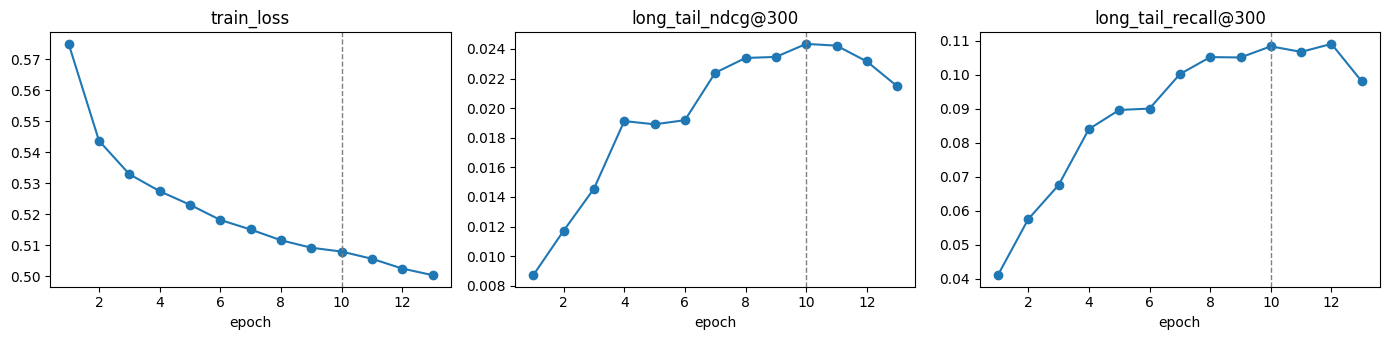

In [32]:
early_stop_requests = np.sort(RNG.choice(NICHE_IMPRESSIONS, size=min(EARLY_STOP_SAMPLE, NICHE_IMPRESSIONS.size),
                                         replace=False))
CHECK_DEPTH = max(NDCG_K, RECALL_K)


def model_scorer(net, article_vectors, requests):
    # Score every article for a batch of requests
    def score_fn(idx):
        users = net.user_vectors(requests.hist_tail[idx], article_vectors)
        return net.score(users, article_vectors, requests.ts[idx], ALL_ROWS)
    return score_fn


model = NicheTwoTower().to(DEVICE)
optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history, best_score, best_state, no_improvement = [], -1.0, None, 0

for epoch in range(1, EPOCHS + 1):
    started = time.time()

    # Random negative sampling for this epoch: new shown-but-not-clicked negatives
    # (epoch 1 uses the draw from Step 9; iter_training_epoch counts epochs from 0)
    if NEGATIVE_SOURCE in ('shown', 'both'):
        SHOWN_NEG = FIRST_SHOWN if epoch == 1 else draw_shown(epoch - 1)

    # Training: one pass over all clicks in random order
    model.train()
    losses = []
    order = RNG.permutation(POS_REQ.size)
    for s in range(0, order.size, BATCH):
        batch = order[s:s + BATCH]
        req, positive = POS_REQ[batch], POS_ROW[batch]
        negatives, ignore = sample_negatives(batch)
        article_vectors = model.article_vectors()
        users = model.user_vectors(TRAIN.hist_tail[req], article_vectors)
        candidates = torch.from_numpy(np.concatenate([positive[:, None], negatives], axis=1)).to(DEVICE)
        loss = training_loss(model.score(users, article_vectors, TRAIN.ts[req], candidates), ignore)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        losses.append(loss.item())

    # Validation: niche lists for the fixed sample of requests
    model.eval()
    with torch.no_grad():
        lists = top_niche(model_scorer(model, model.article_vectors(), VAL), VAL, VAL_POPULAR, CHECK_DEPTH,
                          subset=early_stop_requests)
    scores = niche_metrics(lists, subset=early_stop_requests)

    # Early stopping: keep the best epoch by the selected score
    improved = scores[SELECT_METRIC] > best_score
    if improved:
        best_score, best_state, no_improvement = scores[SELECT_METRIC], copy.deepcopy(model.state_dict()), 0
    else:
        no_improvement += 1
    history.append({'epoch': epoch, 'train_loss': float(np.mean(losses)), NDCG_NAME: scores[NDCG_NAME],
                    RECALL_NAME: scores[RECALL_NAME], 'seconds': round(time.time() - started, 1)})
    print(f'epoch {epoch:02d} | {LOSS} loss {np.mean(losses):.4f} | {NDCG_NAME} {scores[NDCG_NAME]:.4f} | '
          f'{RECALL_NAME} {scores[RECALL_NAME]:.4f} | {time.time() - started:.0f}s'
          f'{" | BEST" if improved else f" | patience {no_improvement}/{PATIENCE}"}')
    if no_improvement >= PATIENCE:
        print(f'Early stopping after epoch {epoch}')
        break

# Restore and save the best epoch
model.load_state_dict(best_state)
torch.save({k: v.cpu() for k, v in best_state.items()}, OUTPUT_DIR / 'model.pt')
TRAINING_HISTORY = pl.DataFrame(history)
TRAINING_HISTORY.write_csv(OUTPUT_DIR / 'training_history.csv')
BEST_EPOCH = int(TRAINING_HISTORY.sort(SELECT_METRIC)['epoch'][-1])
print(f'Best epoch by {SELECT_METRIC}: {BEST_EPOCH}')

# Plot loss and validation scores per epoch
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column in zip(axes, ('train_loss', NDCG_NAME, RECALL_NAME)):
    ax.plot(TRAINING_HISTORY['epoch'], TRAINING_HISTORY[column], marker='o')
    ax.axvline(BEST_EPOCH, color='grey', linestyle='--', linewidth=1)
    ax.set(title=column, xlabel='epoch')
plt.tight_layout()
plt.show()

## Step 11: Generate and Evaluate Niche Candidates

Use the best model to retrieve 750 niche candidates for each validation request. Save the ranked lists, calculate niche Recall@K and NDCG@K, and run the group's shared evaluation at cutoffs from 50 to 750. Record model settings and scores for comparison across runs.


In [33]:
# Niche lists for every validation request
with torch.no_grad():
    NICHE_TOP = top_niche(model_scorer(model, model.article_vectors(), VAL), VAL, VAL_POPULAR, NICHE_DEPTH)
NICHE_FILE = save_lists(OUTPUT_DIR / 'recommendations_validation.parquet', VAL, NICHE_TOP)
NICHE_METRICS = niche_metrics(NICHE_TOP)
print({k: round(v, 4) for k, v in NICHE_METRICS.items()})

# Record this run's settings and scores (one row per setting combination)
summary_path = OUTPUT_DIR / 'run_summary.csv'
run = pl.DataFrame([{'negative_source': NEGATIVE_SOURCE, 'negatives': NEGATIVES, 'train_on': TRAIN_ON,
                     'loss': LOSS, 'select_by': SELECT_BY, 'best_epoch': BEST_EPOCH, **NICHE_METRICS}])
settings = ['negative_source', 'negatives', 'train_on', 'loss', 'select_by']
if summary_path.exists():
    previous = pl.read_csv(summary_path).join(run.select(settings), on=settings, how='anti')
    run = pl.concat([previous, run], how='diagonal_relaxed')
run.sort(NDCG_NAME, descending=True).write_csv(summary_path)

# Shared evaluation (also updates the group's comparison CSV)
EVALUATION = EVALUATOR.evaluate_to_csv(NICHE_FILE, model_name=MODEL_NAME, m_values=EVAL_M, output_dir=RESULTS)
wide_table(EVALUATION)

{'long_tail_ndcg@300': 0.0243, 'long_tail_recall@50': 0.0408, 'long_tail_recall@100': 0.059, 'long_tail_recall@200': 0.087, 'long_tail_recall@300': 0.1083}


model,split,m,catalogue_coverage,cold_article_recall,hit_rate,long_tail_recall,novelty_bits,personalisation,recall_impression_mean,recall_pooled
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""niche_two_tower""","""validation""",50,0.369557,0.128655,0.012238,0.040806,15.685787,0.964442,0.007819,0.008319
"""niche_two_tower""","""validation""",100,0.511465,0.154971,0.017708,0.05901,15.695011,0.959256,0.011176,0.012031
"""niche_two_tower""","""validation""",150,0.598931,0.181287,0.021977,0.073737,15.69929,0.954939,0.013888,0.015033
"""niche_two_tower""","""validation""",200,0.663196,0.207602,0.025803,0.087032,15.701903,0.951502,0.016295,0.017744
"""niche_two_tower""","""validation""",250,0.713492,0.24269,0.02906,0.098384,15.70373,0.948354,0.01839,0.020058
…,…,…,…,…,…,…,…,…,…,…
"""niche_two_tower""","""validation""",550,0.862005,0.307018,0.042721,0.146451,15.708982,0.933918,0.027311,0.029858
"""niche_two_tower""","""validation""",600,0.874416,0.309942,0.044713,0.153406,15.709457,0.931934,0.028545,0.031275
"""niche_two_tower""","""validation""",650,0.886806,0.315789,0.046768,0.160974,15.709893,0.929959,0.029817,0.032818


## Step 12: Select the Niche Candidate Count Using the Elbow Method

Calculate niche Recall@K for candidate depths from 10 to 750. Use the maximum-distance elbow method to identify a point where additional niche candidates bring diminishing recall gains. Plot both the recall curve and the incremental gain per 10 candidates, then save the results for choosing the final niche allocation.

The elbow is a selection heuristic rather than proof of the globally optimal K; the final allocation remains configurable.

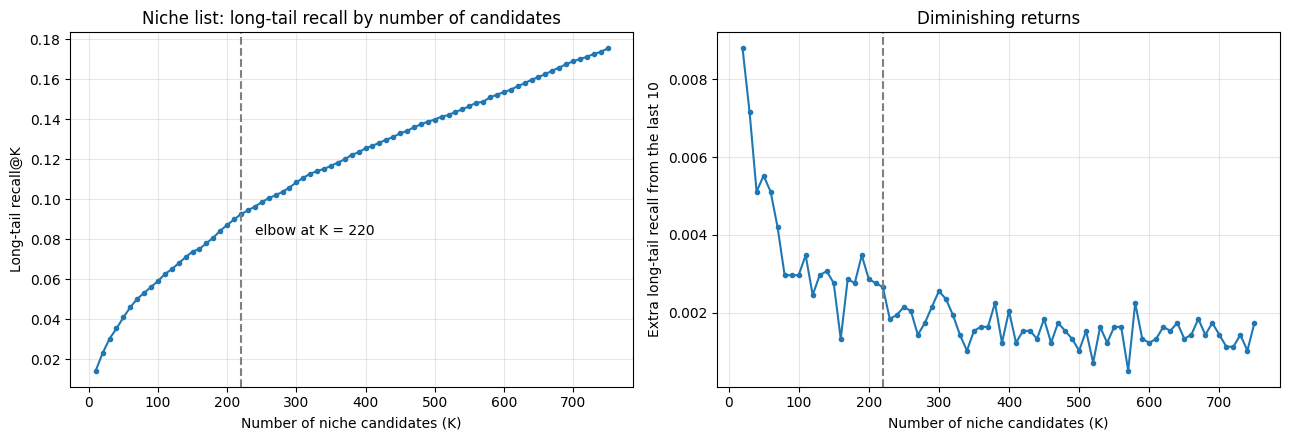

Elbow at K = 220: long-tail recall 0.092 (vs 0.175 at K = 750)


In [34]:
# Measure niche-click recall across candidate-list depths
match = NICHE_TOP[NICHE_REQ] == NICHE_ROW[:, None]
rank = np.where(match.any(axis=1), match.argmax(axis=1) + 1, 0)
CURVE_K = np.arange(10, NICHE_DEPTH + 1, 10)
curve = np.array([((rank > 0) & (rank <= k)).mean() for k in CURVE_K])
gain = np.r_[curve[0], np.diff(curve)]

# Find the elbow by maximum distance above the normalized endpoint line
x = (CURVE_K - CURVE_K[0]) / (CURVE_K[-1] - CURVE_K[0])
y = (curve - curve[0]) / max(curve[-1] - curve[0], 1e-12)
ELBOW_K = int(CURVE_K[np.argmax(y - x)])

pl.DataFrame({'k': CURVE_K, 'long_tail_recall': curve, 'gain_per_10_slots': gain}).write_csv(
    OUTPUT_DIR / 'long_tail_recall_curve.csv')

# Plot recall and marginal gain for additional niche candidates
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(CURVE_K, curve, marker='o', markersize=3)
ax1.annotate(f'elbow at K = {ELBOW_K}', (ELBOW_K, curve[CURVE_K == ELBOW_K][0]), textcoords='offset points', xytext=(10, -15))
ax1.set(xlabel='Number of niche candidates (K)', ylabel='Long-tail recall@K', title='Niche list: long-tail recall by number of candidates')
ax2.plot(CURVE_K[1:], gain[1:], marker='o', markersize=3)
ax2.set(xlabel='Number of niche candidates (K)', ylabel='Extra long-tail recall from the last 10', title='Diminishing returns')
for ax in (ax1, ax2):
    ax.axvline(ELBOW_K, linestyle='--', color='grey')
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'long_tail_recall_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Elbow at K = {ELBOW_K}: long-tail recall {curve[CURVE_K == ELBOW_K][0]:.3f} (vs {curve[-1]:.3f} at K = {CURVE_K[-1]})')


## Step 13: Analyse Where Niche Clicks Come From

Examine the positions of niche-clicked articles in the popularity baseline's saved ranking (ranks beyond the saved depth are grouped together) and the ages of those articles when clicked. This helps explain which articles the popular top 200 misses and whether the niche opportunity is concentrated in newer articles.

In [35]:
# Rank of each niche click in the popularity channel's saved list
ranked = (pl.DataFrame({'req': NICHE_REQ, 'news_code': CODE_OF_ROW[NICHE_ROW]})
          .join(pl.scan_parquet(POPULAR_FILE).select('impression_uid', 'cutoff', 'news_code').collect()
                .join(pl.DataFrame({'impression_uid': VAL.uid, 'req': np.arange(VAL.uid.size)}), on='impression_uid')
                .select('req', 'news_code', 'cutoff'), on=['req', 'news_code'], how='left'))
popular_rank = ranked['cutoff'].to_numpy(allow_copy=True).astype(float)

print('Niche clicks by rank in the popular list:')
low = POPULAR_TOP_N
for high in [b for b in (300, 500, 1000) if b < POPULAR_DEPTH] + [POPULAR_DEPTH]:
    print(f'  rank {low + 1:>4}-{high:<5}: {((popular_rank > low) & (popular_rank <= high)).mean():6.1%}')
    low = high
print(f'  beyond rank {POPULAR_DEPTH}: {np.isnan(popular_rank).mean():6.1%}')

# Age of the clicked article at the time of the click
age_hours = (VAL.ts[NICHE_REQ] - AVAIL_NS[NICHE_ROW]) / HOUR_NS
print('\nAge of the clicked niche article:')
for limit in (6, 24, 48, 96):
    print(f'  under {limit:>2}h: {(age_hours < limit).mean():6.1%}')

Niche clicks by rank in the popular list:
  rank  201-300  :  28.3%
  rank  301-500  :  25.3%
  beyond rank 500:  46.4%

Age of the clicked niche article:
  under  6h:  23.7%
  under 24h:  69.2%
  under 48h:  84.8%
  under 96h:  90.8%
